# Banka Kampanyası: Geliştirilmiş Model

`lesson.ipynb` içindeki Logistic Regression modelinin skorunu geçmek için hazırlandı.
Veri, split (%70 train, %15 test, %15 live, dosya sırasına göre) ve `duration`'ın çıkarılması **orijinaliyle aynı**.

| | Orijinal | Bu notebook |
|---|---|---|
| Test ROC-AUC | 0.661 | aşağıda hesaplanıyor |
| Live ROC-AUC (hiç kullanılmayan dönem) | ölçülmemişti | aşağıda hesaplanıyor |

İki aşamada ilerliyorum:
1. **Daha iyi bir model** (bir kez eğitilen, orijinaliyle aynı düzende).
2. **Sürekli eğitim (continuous training):** Modeli her 250 görüşmede, o ana kadar biriken verilerle yeniden eğitmek.

**Değerlendirme düzeni:** Model ve eşik seçimi **test** döneminde yapılıyor (validation görevi görüyor). **Live** dönemi seçimde hiç kullanılmıyor, en sonda bir kez bakılıyor.

## 1. Kütüphaneler

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler

## 2. Ayarlar

In [2]:
DATA_PATH = Path("data/bank-additional-full.csv")
SERVE_DIR = Path("serve")

TRAIN_END, TEST_END = 0.70, 0.85               # orijinal split
LEAKY_COLS = ["duration"]                      # görüşme bitmeden bilinmiyor
MACRO_COLS = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

HALF_LIFE = 2000      # yakın geçmiş ağırlığı: 2000 satır önceki görüşme yarı ağırlık alır
C = 0.01              # regularization gücü (küçük C = daha güçlü regularization)
RETRAIN_EVERY = 250   # sürekli eğitimde model kaç görüşmede bir yeniden eğitilir

## 3. Yardımcı fonksiyonlar

In [3]:
def load_data(path):
    df = pd.read_csv(path, sep=";")
    X = df.drop(columns=LEAKY_COLS + ["y"])
    y = (df["y"] == "yes").astype(int)
    return X, y


def time_split(X, y):
    train_end, test_end = int(len(X) * TRAIN_END), int(len(X) * TEST_END)
    parts = {"train": slice(0, train_end), "test": slice(train_end, test_end), "live": slice(test_end, None)}
    return {name: (X.iloc[s], y.iloc[s]) for name, s in parts.items()}


def column_types(X, drop=()):
    cols = [c for c in X.columns if c not in drop]
    numeric = [c for c in cols if pd.api.types.is_numeric_dtype(X[c])]
    categorical = [c for c in cols if c not in numeric]
    return numeric, categorical


def build_logreg(numeric, categorical, C=1.0, age_spline=False):
    """Listede olmayan sütunlar (örn. makro sütunlar) ColumnTransformer tarafından atılır.
    age_spline=True: yaş tek bir doğru yerine eğrisel (spline) olarak modellenir."""
    transformers = []
    if age_spline:
        transformers.append(("age", SplineTransformer(n_knots=5, degree=3), ["age"]))
        numeric = [c for c in numeric if c != "age"]
    transformers += [
        ("numbers", StandardScaler(), numeric),
        ("categories", OneHotEncoder(handle_unknown="ignore"), categorical),
    ]
    return Pipeline([
        ("prep", ColumnTransformer(transformers)),
        ("model", LogisticRegression(max_iter=5000, class_weight="balanced", C=C)),
    ])


def recency_weights(n_rows, half_life):
    """En yeni satır 1, half_life satır öncesi 0.5, 2*half_life öncesi 0.25 ağırlık alır."""
    rows_ago = np.arange(n_rows)[::-1]
    return 0.5 ** (rows_ago / half_life)


def fit(model, X, y, half_life=None):
    weights = None if half_life is None else recency_weights(len(X), half_life)
    return model.fit(X, y, model__sample_weight=weights)


def walk_forward(make_model, X_all, y_all, start, end, every, half_life=None):
    """start..end arasındaki satırları 'every' satırlık parçalar halinde tahmin eder.
    Her parça, SADECE o parçadan önceki satırlarla eğitilen yeni bir modelle tahmin edilir."""
    probabilities = np.empty(end - start)
    for chunk_start in range(start, end, every):
        chunk_end = min(chunk_start + every, end)
        model = fit(make_model(), X_all.iloc[:chunk_start], y_all.iloc[:chunk_start], half_life)
        probabilities[chunk_start - start:chunk_end - start] = model.predict_proba(X_all.iloc[chunk_start:chunk_end])[:, 1]
    return probabilities


def scores(y, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y, p),
        "PR-AUC": average_precision_score(y, p),
        "F1 (yes)": f1_score(y, pred),
        "Precision (yes)": precision_score(y, pred, zero_division=0),
        "Recall (yes)": recall_score(y, pred),
        "Accuracy": accuracy_score(y, pred),
        "'yes' denen oran": pred.mean(),
    }


def evaluate(model, X, y, threshold=0.5):
    return scores(y, model.predict_proba(X)[:, 1], threshold)


def best_f1_threshold(y, p):
    precision, recall, thresholds = precision_recall_curve(y, p)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    return float(thresholds[np.argmax(f1[:-1])])


def psi(train_values, live_values, numeric):
    """Population Stability Index: <0.10 stabil, <0.20 küçük kayma, >=0.20 drift."""
    if numeric:
        edges = np.unique(np.quantile(train_values, np.linspace(0, 1, 11)))
        if len(edges) == 1:
            edges = np.array([edges[0] - 1, edges[0] + 1])
        train_share = np.histogram(train_values, edges)[0] / len(train_values)
        live_share = np.histogram(np.clip(live_values, edges[0], edges[-1]), edges)[0] / len(live_values)
    else:
        train_counts = pd.Series(train_values).astype(str).value_counts(normalize=True)
        live_counts = pd.Series(live_values).astype(str).value_counts(normalize=True)
        categories = train_counts.index.union(live_counts.index)
        train_share = train_counts.reindex(categories, fill_value=0).to_numpy()
        live_share = live_counts.reindex(categories, fill_value=0).to_numpy()
    train_share = np.clip(train_share, 1e-4, None); train_share /= train_share.sum()
    live_share = np.clip(live_share, 1e-4, None); live_share /= live_share.sum()
    return float(np.sum((live_share - train_share) * np.log(live_share / train_share)))


def drift_status(score):
    return "stabil" if score < 0.10 else ("küçük kayma" if score < 0.20 else "drift")

## 4. Veriyi yükle ve böl

In [4]:
X, y = load_data(DATA_PATH)
split = time_split(X, y)
X_train, y_train = split["train"]
X_test, y_test = split["test"]
X_live, y_live = split["live"]

pd.DataFrame({name: {"satır": len(yy), "'yes' oranı": round(yy.mean(), 3)} for name, (_, yy) in split.items()})

,train,test,live
satır,28831.000,6178.000,6179.000
'yes' oranı,0.056,0.107,0.385


## 5. Orijinal modeli birebir yeniden üret (baseline)
`lesson.ipynb` ile aynı: bütün sütunlar, StandardScaler + OneHot, `LogisticRegression(class_weight="balanced")`, eşik 0.5.

In [5]:
all_numeric, all_categorical = column_types(X_train)
baseline = fit(build_logreg(all_numeric, all_categorical), X_train, y_train)

results = {"Orijinal (baseline)": evaluate(baseline, X_test, y_test)}
pd.DataFrame(results).T.round(3)

,ROC-AUC,PR-AUC,F1 (yes),Precision (yes),Recall (yes),Accuracy,'yes' denen oran
Orijinal (baseline),0.661,0.19,0.211,0.119,0.942,0.249,0.845


## 6. Orijinal model neden zorlanıyor?

**1) Makro ekonomik sütunlar dönemden döneme tamamen değişiyor.** Faiz (`euribor3m`), istihdam (`nr.employed`) gibi sütunlar müşteriyle ilgili değil, **o günün ekonomisiyle** ilgili. 2008'den 2009'a ekonomi çöktü, değerler eğitimde hiç görülmemiş aralıklara düştü:

In [6]:
pd.DataFrame({
    name: {col: f"{part[col].min():.2f} … {part[col].max():.2f}" for col in MACRO_COLS}
    for name, (part, _) in split.items()
})

,train,test,live
emp.var.rate,-1.80 … 1.40,-1.80 … -1.80,-3.40 … -1.10
cons.price.idx,92.76 … 94.47,92.89 … 93.08,92.20 … 94.77
cons.conf.idx,-50.00 … -36.10,-47.10 … -46.20,-50.80 … -26.90
euribor3m,1.41 … 5.04,1.25 … 1.41,0.63 … 1.29
nr.employed,5099.10 … 5228.10,5099.10 … 5099.10,4963.60 … 5099.10


Model eğitimde "faiz düştükçe abonelik artıyor" öğreniyor. Testte faiz eğitimdeki en düşük değerin de altında olunca bu kuralı **dışarı taşıyor (extrapolation)** ve neredeyse herkese "yes" diyor:

In [7]:
yes_share = results["Orijinal (baseline)"]["'yes' denen oran"]
print(f"Orijinal model test döneminde müşterilerin %{100 * yes_share:.0f}'ine 'yes' diyor.")
print(f"Gerçekte abone olanların oranı: %{100 * y_test.mean():.0f}")

Orijinal model test döneminde müşterilerin %85'ine 'yes' diyor.
Gerçekte abone olanların oranı: %11


**2) Eski veri bugünü temsil etmiyor.** Eğitim verisinin büyük kısmı 2008 yazından; o dönemde abone olma oranı %3–6 ve "önceki kampanya" bilgisi hiç yok. Test dönemi (2009 baharı) çok farklı:

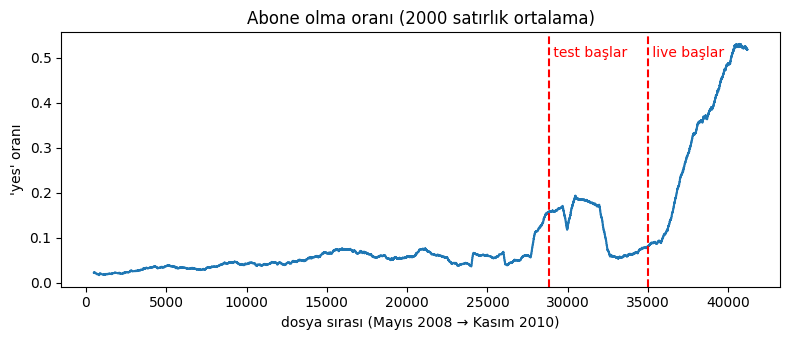

In [8]:
subscribed = y.astype(float)
ax = subscribed.rolling(2000, min_periods=500).mean().plot(figsize=(8, 3.5), title="Abone olma oranı (2000 satırlık ortalama)")
train_end, test_end = int(len(X) * TRAIN_END), int(len(X) * TEST_END)
for x, label in [(train_end, "test başlar"), (test_end, "live başlar")]:
    ax.axvline(x, color="red", linestyle="--"); ax.text(x, ax.get_ylim()[1] * 0.9, " " + label, color="red")
ax.set_xlabel("dosya sırası (Mayıs 2008 → Kasım 2010)"); ax.set_ylabel("'yes' oranı")
plt.tight_layout(); plt.show()

## 7. İyileştirmeler (adım adım)

| Adım | Ne | Neden |
|---|---|---|
| a | Makro sütunları çıkar | Eğitimde görülmeyen değerlere taşan, en çok drift yapan sütunlar bunlar |
| b | Yakın geçmişe daha fazla ağırlık (`sample_weight`) | Test dönemine en çok benzeyen veri, eğitimin son ayları |
| c | Güçlü regularization (`C=0.01`) | Az sayıdaki yakın tarihli örneğe aşırı uymayı engeller |
| d | Yaşı eğrisel modelle (spline) | Abone olma oranı yaşla düz artmıyor: gençlerde (öğrenciler) ve yaşlılarda (emekliler) yüksek, ortada düşük |

In [9]:
numeric, categorical = column_types(X_train, drop=MACRO_COLS)
steps = {
    "a) makro sütunlar yok": (build_logreg(numeric, categorical), None),
    "b) + yakın geçmiş ağırlığı": (build_logreg(numeric, categorical), HALF_LIFE),
    "c) + regularization": (build_logreg(numeric, categorical, C=C), HALF_LIFE),
    "d) + yaş spline (FİNAL)": (build_logreg(numeric, categorical, C=C, age_spline=True), HALF_LIFE),
}
for name, (model, half_life) in steps.items():
    results[name] = evaluate(fit(model, X_train, y_train, half_life), X_test, y_test)

pd.DataFrame(results).T[["ROC-AUC", "PR-AUC"]].round(4)

,ROC-AUC,PR-AUC
Orijinal (baseline),0.6608,0.1902
a) makro sütunlar yok,0.6613,0.1988
b) + yakın geçmiş ağırlığı,0.6706,0.2150
c) + regularization,0.6904,0.2507
d) + yaş spline (FİNAL),0.6952,0.2569


### Ayar seçimi: neden `HALF_LIFE=2000`, `C=0.01`?
Birkaç değeri denedim. Skorlar geniş bir bölgede birbirine yakın (bir plato). En yüksek değeri değil, platonun **ortasını** seçtim; böylece teste aşırı uydurma riski azalıyor.

In [10]:
grid = pd.DataFrame(
    {c: {hl: roc_auc_score(y_test, fit(build_logreg(numeric, categorical, C=c, age_spline=True), X_train, y_train, hl).predict_proba(X_test)[:, 1])
         for hl in [1500, 2000, 3000, 4000]}
     for c in [0.003, 0.01, 0.03]}
)
grid.index.name = "HALF_LIFE \\ C"
grid.round(4)

,0.003,0.010,0.030
HALF_LIFE \ C,,,
1500,0.6874,0.6912,0.6880
2000,0.6940,0.6952,0.6902
3000,0.7000,0.6983,0.6921
4000,0.7030,0.6964,0.6856


## 8. Karar eşiği
Orijinal model 0.5 eşiğini kullanıyor ve neredeyse herkese "yes" diyor. Final model için eşiği, test döneminde **F1 (yes)** skorunu en yüksek yapan değere ayarlıyorum.

In [11]:
make_final = lambda: build_logreg(numeric, categorical, C=C, age_spline=True)
final = fit(make_final(), X_train, y_train, HALF_LIFE)
threshold = best_f1_threshold(y_test, final.predict_proba(X_test)[:, 1])
results["FİNAL + ayarlı eşik"] = evaluate(final, X_test, y_test, threshold)
print(f"Seçilen eşik: {threshold:.3f}")

Seçilen eşik: 0.600


## 9. Test sonuçları: orijinal ve final

In [12]:
summary = pd.DataFrame(results).T.loc[["Orijinal (baseline)", "d) + yaş spline (FİNAL)", "FİNAL + ayarlı eşik"]]
summary.round(3)

,ROC-AUC,PR-AUC,F1 (yes),Precision (yes),Recall (yes),Accuracy,'yes' denen oran
Orijinal (baseline),0.661,0.190,0.211,0.119,0.942,0.249,0.845
d) + yaş spline (FİNAL),0.695,0.257,0.253,0.154,0.716,0.550,0.496
FİNAL + ayarlı eşik,0.695,0.257,0.313,0.302,0.325,0.848,0.115


## 10. Sürekli eğitim (continuous training)

Orijinal düzende model bir kez eğitilip bir daha hiç güncellenmiyor. Oysa müşterinin abone olup olmadığı **görüşmenin sonunda** belli oluyor. Banka modeli düzenli aralıklarla, o ana kadar biriken verilerle yeniden eğitebilir. 250 görüşme, test döneminde yaklaşık 1 güne, aramaların seyrekleştiği live döneminde ise yaklaşık 2 haftaya denk geliyor.

Bunu simüle ediyorum: Test dönemini 250 görüşmelik parçalara bölüyorum. Her parça, **sadece o parçadan önceki görüşmelerle** eğitilmiş yeni bir modelle tahmin ediliyor. Yani hiçbir tahmin, o görüşme anında bilinmeyen bir bilgiyi kullanmıyor (geleceğe bakmak yok).

**Makro sütunlar burada geri geliyor.** Makro sütunların sorunu, bir kez eğitilen modelin eski ekonomik değerlere takılı kalmasıydı. Model her 250 görüşmede yeniden eğitilince bu sütunlar hep güncel ekonomiyi yansıtıyor ve faydalı hale geliyor. Test döneminde birkaç seçeneği denedim, en iyisi makro sütunların da kullanıldığı versiyon oldu.

Adil olsun diye orijinal modele de aynı imkânı tanıyorum.

In [13]:
make_baseline = lambda: build_logreg(all_numeric, all_categorical)
make_final_retrain = lambda: build_logreg(all_numeric, all_categorical, C=C, age_spline=True)   # makro sütunlar dahil
train_end, test_end = int(len(X) * TRAIN_END), int(len(X) * TEST_END)
RETRAINED = f"FİNAL, her {RETRAIN_EVERY} görüşmede yeniden eğitim"

ct_test = {
    "Orijinal, yeniden eğitim yok": baseline.predict_proba(X_test)[:, 1],
    "FİNAL, yeniden eğitim yok": final.predict_proba(X_test)[:, 1],
    f"Orijinal, her {RETRAIN_EVERY} görüşmede yeniden eğitim": walk_forward(make_baseline, X, y, train_end, test_end, RETRAIN_EVERY),
    RETRAINED: walk_forward(make_final_retrain, X, y, train_end, test_end, RETRAIN_EVERY, HALF_LIFE),
}
ct_threshold = best_f1_threshold(y_test, ct_test[RETRAINED])
ct_results = pd.DataFrame({name: scores(y_test, p) for name, p in ct_test.items()}).T
ct_results.loc[RETRAINED + " + ayarlı eşik"] = scores(y_test, ct_test[RETRAINED], ct_threshold)
print(f"Sürekli eğitim için seçilen eşik: {ct_threshold:.3f}")
ct_results.round(3)

Sürekli eğitim için seçilen eşik: 0.584


,ROC-AUC,PR-AUC,F1 (yes),Precision (yes),Recall (yes),Accuracy,'yes' denen oran
"Orijinal, yeniden eğitim yok",0.661,0.190,0.211,0.119,0.942,0.249,0.845
"FİNAL, yeniden eğitim yok",0.695,0.257,0.253,0.154,0.716,0.550,0.496
"Orijinal, her 250 görüşmede yeniden eğitim",0.667,0.191,0.221,0.126,0.904,0.321,0.765
"FİNAL, her 250 görüşmede yeniden eğitim",0.708,0.259,0.283,0.179,0.669,0.639,0.397
"FİNAL, her 250 görüşmede yeniden eğitim + ayarlı eşik",0.708,0.259,0.338,0.269,0.453,0.811,0.179


## 11. Son sınav: live dönemi
Live dönemi (Mayıs 2009 sonu – Kasım 2010) **hiçbir seçimde kullanılmadı**. Model ve eşik test döneminde belirlendi, burada sadece bir kez ölçüyoruz.

In [14]:
live_baseline_retrain = walk_forward(make_baseline, X, y, test_end, len(X), RETRAIN_EVERY)
live_retrain = walk_forward(make_final_retrain, X, y, test_end, len(X), RETRAIN_EVERY, HALF_LIFE)
live_results = pd.DataFrame({
    "Orijinal, yeniden eğitim yok": evaluate(baseline, X_live, y_live),
    "FİNAL, yeniden eğitim yok (ayarlı eşik)": evaluate(final, X_live, y_live, threshold),
    f"Orijinal, her {RETRAIN_EVERY} görüşmede yeniden eğitim": scores(y_live, live_baseline_retrain),
    RETRAINED + " (ayarlı eşik)": scores(y_live, live_retrain, ct_threshold),
}).T
live_results.round(3)

,ROC-AUC,PR-AUC,F1 (yes),Precision (yes),Recall (yes),Accuracy,'yes' denen oran
"Orijinal, yeniden eğitim yok",0.563,0.438,0.540,0.392,0.867,0.431,0.851
"FİNAL, yeniden eğitim yok (ayarlı eşik)",0.595,0.497,0.386,0.529,0.304,0.628,0.221
"Orijinal, her 250 görüşmede yeniden eğitim",0.693,0.568,0.571,0.404,0.973,0.437,0.927
"FİNAL, her 250 görüşmede yeniden eğitim (ayarlı eşik)",0.678,0.559,0.576,0.469,0.746,0.578,0.611


- **Live döneminde de ROC-AUC ve PR-AUC arttı**, yani kazanç teste uydurmaktan kaynaklanmıyor.
- **Asıl büyük fark sürekli eğitimde.** Live dönemi 17 ayı kapsıyor ve aylık abone oranı %14 ile %57 arasında değişiyor (test döneminde %11'di). Bir kez eğitilen model bu değişimi göremiyor; düzenli yeniden eğitilen model ise güncel kalıyor. Bu dönemde orijinal model bile yeniden eğitilince büyük ölçüde toparlanıyor; yani uzun vadede **modeli güncel tutmak, modeli değiştirmekten daha önemli**.
- Yeniden eğitim olmadan, test dönemine göre seçilen eşik live döneminde az "yes" diyor ve F1 düşüyor. Bu bir **drift** belirtisi; aşağıdaki drift tablosu da bunu destekliyor.

## 12. Modeli ve servisi kaydet

In [15]:
SERVE_DIR.mkdir(exist_ok=True)
joblib.dump(final, SERVE_DIR / "model.joblib")

numeric_all, categorical_all = column_types(X_train)
reference = {"numeric": {}, "categorical": {}}
for name in numeric_all:
    edges = np.unique(np.quantile(X_train[name], np.linspace(0, 1, 11)))
    if len(edges) == 1:
        edges = np.array([edges[0] - 1, edges[0] + 1])
    counts, _ = np.histogram(X_train[name], bins=edges)
    reference["numeric"][name] = {"edges": edges.tolist(), "share": (counts / counts.sum()).tolist()}
for name in categorical_all:
    reference["categorical"][name] = X_train[name].astype(str).value_counts(normalize=True).to_dict()
(SERVE_DIR / "reference.json").write_text(json.dumps(reference))

APP_TEMPLATE = '''
import json
import os
from pathlib import Path

import joblib
import pandas as pd
from fastapi import FastAPI

THRESHOLD = {threshold}

model = joblib.load(Path(__file__).resolve().parent / "model.joblib")
log_path = Path(os.environ.get("LOG_PATH", "/logs/requests.jsonl"))
app = FastAPI()

@app.get("/health")
def health():
    return {{"status": "ok"}}

@app.post("/predict")
def predict(row: dict):
    log_path.parent.mkdir(parents=True, exist_ok=True)
    with log_path.open("a") as handle:
        handle.write(json.dumps(row) + "\\n")
    frame = pd.DataFrame([row])
    probability = float(model.predict_proba(frame)[0, 1])
    label = "yes" if probability >= THRESHOLD else "no"
    return {{"label": label, "probability": round(probability, 4)}}
'''
(SERVE_DIR / "app.py").write_text(APP_TEMPLATE.format(threshold=round(threshold, 4)).strip() + "\n")
print("kaydedildi:", sorted(p.name for p in SERVE_DIR.iterdir()))

kaydedildi: ['.dockerignore', 'Dockerfile', 'app.py', 'model.joblib', 'reference.json', 'requirements.txt']


Kaydedilen model, eğitim döneminin tamamıyla eğitilmiş FİNAL model. Sürekli eğitimde bu adım (eğit → `model.joblib` → servisi yeniden başlat) her 250 görüşmede bir tekrarlanır; örneğin düzenli çalışan otomatik bir iş olarak.

Servis yine bütün sütunları içeren satırı kabul ediyor; model ihtiyaç duymadığı makro sütunları kendisi atıyor. Docker adımları `lesson.ipynb` ile aynı:
```bash
docker build -t bank-campaign ./serve
docker run --rm -p 8000:8000 -v "$PWD/logs:/logs" bank-campaign
```

## 13. Drift (PSI): live dönemi eğitimden ne kadar farklı?
Orijinal notebook'taki PSI hesabı burada tek bir `psi()` fonksiyonuna toplandı.

In [16]:
drift = pd.DataFrame([
    {"sütun": col, "psi": round(psi(X_train[col], X_live[col], col in numeric_all), 3),
     "modelde var mı": "hayır (çıkarıldı)" if col in MACRO_COLS else "evet"}
    for col in numeric_all + categorical_all
])
drift["durum"] = drift["psi"].map(drift_status)
drift.sort_values("psi", ascending=False).reset_index(drop=True)

,sütun,psi,modelde var mı,durum
0,emp.var.rate,11.517,hayır (çıkarıldı),drift
1,nr.employed,11.324,hayır (çıkarıldı),drift
2,euribor3m,8.484,hayır (çıkarıldı),drift
3,cons.price.idx,3.896,hayır (çıkarıldı),drift
4,cons.conf.idx,3.204,hayır (çıkarıldı),drift
5,poutcome,1.506,evet,drift
6,month,1.385,evet,drift
7,contact,0.654,evet,drift
8,default,0.471,evet,drift
9,job,0.469,evet,drift


En çok drift yapan beş sütun, bir kez eğitilen final modelden çıkardığım makro sütunlar. Bu model artık bu sütunlara bağlı olmadığı için dönem değiştiğinde daha dayanıklı. Sürekli eğitilen modelde ise bu sütunlar her eğitimde güncellendiği için sorun olmaktan çıkıyor.

## 14. Neden zamana göre bölme? Rastgele bölme ile karşılaştırma

Bu veriyi rastgele bölmek (`train_test_split(..., stratify=y)`) çok daha yüksek skorlar verir. Ama o zaman model 2010 görüşmelerini görerek 2008'i tahmin edebilir; yani geleceği bilerek geçmişi tahmin eder. Gerçek hayatta banka geleceği bilemez. Bu yüzden dersin zamana göre bölmesini değiştirmedim.

Farkı görmek için **orijinal ders modelini** iki şekilde ölçüyorum:

In [17]:
df_random = pd.read_csv(DATA_PATH, sep=";").drop_duplicates().drop(columns=LEAKY_COLS)
X_r, y_r = df_random.drop(columns=["y"]), (df_random["y"] == "yes").astype(int)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_r, y_r, test_size=0.20, random_state=42, stratify=y_r)
random_baseline = fit(build_logreg(all_numeric, all_categorical), Xr_train, yr_train)

pd.DataFrame({
    "Orijinal model ROC-AUC": {
        "Zamana göre bölme (dersin kuralı)": roc_auc_score(y_test, baseline.predict_proba(X_test)[:, 1]),
        "Rastgele bölme": roc_auc_score(yr_test, random_baseline.predict_proba(Xr_test)[:, 1]),
    }
}).round(3)

,Orijinal model ROC-AUC
Zamana göre bölme (dersin kuralı),0.661
Rastgele bölme,0.800


Aynı model, sadece bölme şekli değişince ROC-AUC 0.66'dan 0.80'e çıkıyor. Yani rastgele bölmeyle elde edilen skorlar, zamana göre bölmeyle elde edilenlerle **karşılaştırılamaz**. Bu notebook'taki bütün sonuçlar dersin zamana göre bölmesiyle ölçüldü.

## 15. Sonuç
| | Orijinal | FİNAL (bir kez eğitilir) | FİNAL + sürekli eğitim |
|---|---|---|---|
| **Test ROC-AUC** | 0.661 | 0.695 | **0.708** |
| Test F1 (yes), ayarlı eşik | 0.211 | 0.313 | **0.338** |
| Test accuracy, ayarlı eşik | 0.249 | **0.848** | 0.811 |
| **Live ROC-AUC** (seçimde hiç kullanılmadı) | 0.563 | 0.595 | **0.678** |

- Test döneminde ROC-AUC **0.661 → 0.708**. Orijinal model herkese "yes" diyordu; final model seçici davranıyor ve accuracy 0.25'ten 0.81–0.85'e çıkıyor.
- Seçimde hiç kullanılmayan live döneminde de bütün iyileştirmeler korunuyor, en büyük kazanç sürekli eğitimden geliyor.
- Live döneminde orijinal model de yeniden eğitilince ROC-AUC 0.693'e çıkıyor (benimki 0.678); benim model ise orada daha doğru karar veriyor (accuracy 0.58'e karşı 0.44). Yani uzun vadede **en önemli şey modeli güncel tutmak**; bu da MLOps'un çözmeye çalıştığı problemin ta kendisi.
- Model sade bir Logistic Regression olarak kaldı. Fark, hangi veriyi nasıl kullandığımızdan ve modeli nasıl güncel tuttuğumuzdan geliyor.